# Chapter 13: When the Coin Isn't Obeyed: Encouragement, Interference and Switchbacks

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [When the Coin Isn't Obeyed: Encouragement, Interference and Switchbacks](https://books.sugiv.fyi/lift/interference.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import interfere as I, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


glue_num("ab_eff", 100 * I.ab_effect())
glue_num("global_eff", 100 * I.global_effect())
glue_num("global_drop", -100 * I.global_effect())

Here's the finding first. Juno's team tested a more **aggressive model router** that sends 70% of lessons to the large model instead of 30%. A standard A/B test, randomised by learner, said it raises completion by **+1.6 points**. Launched to everyone, it *lowered* completion by **2.4 points**. The large model shares one GPU pool, so the treatment arm's extra traffic slowed down everybody, control included. The A/B test compared two groups stuck in the same traffic jam and never saw the jam.

Every experiment in this book so far has relied on two quiet assumptions: people do what the coin says, and one person's treatment doesn't affect anyone else. This chapter is about what to do when either fails:

- **Learners don't comply** (you can offer Juno, not force it): randomise the *encouragement*.
- **Learners affect each other** (friends, classrooms): randomise *groups*.
- **Treatments share a resource** (GPUs, caches, rate limits): randomise *time*.

> **Note**
>
> The numbers come from `lift/sim/interfere.py`: a "Try Juno" card experiment, friend groups with a leaderboard, and a minute-by-minute simulation of Juno's GPU pool.

## Encouragement: randomise the nudge, not the choice

Chapter 11 left us with a problem. Adjusting for first-week behaviour estimated Juno's effect well, but only if nothing *hidden* drove the choice to use it. If keen learners pick Juno for reasons the logs don't capture, every adjustment fails, and the sensitivity table showed by how much.

Parlo can't randomise Juno itself: it's free, and nobody can be forced to use it. But Parlo *can* randomise a **"Try Juno" card** on the home screen: half of new learners see it, half don't.

In [3]:
E = I.encouragement()
summary = E.groupby(E.nudge.map({0: "no card", 1: "saw the card"})).agg(
    learners=("juno", "size"), used_juno=("juno", "mean"), retained=("retained", "mean"))
summary

,learners,used_juno,retained
nudge,,,
no card,30011,0.282,0.312
saw the card,29989,0.538,0.323


In [4]:
first_stage = E.juno[E.nudge == 1].mean() - E.juno[E.nudge == 0].mean()
itt = E.retained[E.nudge == 1].mean() - E.retained[E.nudge == 0].mean()
late, late_se = I.wald(E.retained, E.juno, E.nudge)
naive = E.retained[E.juno == 1].mean() - E.retained[E.juno == 0].mean()
adj_model = smf.logit("retained ~ juno + lessons_wk1", E).fit(disp=0)
adjusted = (adj_model.predict(E.assign(juno=1)) - adj_model.predict(E.assign(juno=0))).mean()
glue_num("fs", 100 * first_stage)
glue_num("itt", 100 * itt)
glue_num("late", 100 * late)
glue_num("late_lo", 100 * (late - 1.96 * late_se))
glue_num("late_hi", 100 * (late + 1.96 * late_se))
glue_num("iv_naive", 100 * naive)
glue_num("iv_adj", 100 * adjusted)
glue_num("complier_true", 100 * (E.y1 - E.y0)[E.complier == 1].mean())
glue_num("complier_share", 100 * E.complier.mean())

The card raised Juno use by 26 points, and retention by 1.1 points. Both differences are clean experimental results, because the card was assigned by a coin.

The second number is the **intention-to-treat** effect: the effect of *showing the card*. It's small because most learners' Juno use didn't change: many would have used Juno anyway, and many ignored the card. Only the learners the card actually moved could have had their retention changed by it. So divide:

> effect of Juno on the learners the card moved = (card's effect on retention) / (card's effect on Juno use) = 1.14 points / 25.6 points = about 4.4 points.

That's the **instrumental variables** (IV) estimate, here also called the Wald estimator (Angrist et al., 1996):

In [5]:
late, late_se = I.wald(E.retained, E.juno, E.nudge)
pd.Series({
    "naive: Juno users vs non-users": naive,
    "adjusted for first-week lessons (Chapter 11)": adjusted,
    "IV: card effect / card's effect on use": late,
    "truth, for learners the card moved": (E.y1 - E.y0)[E.complier == 1].mean(),
}).mul(100).round(1).to_frame("Juno's effect on retention (points)")

,Juno's effect on retention (points)
naive: Juno users vs non-users,20.0
adjusted for first-week lessons (Chapter 11),16.1
IV: card effect / card's effect on use,4.4
"truth, for learners the card moved",5.1


The naive comparison says 20 points. Adjusting for first-week lessons barely helps (16), because in this world the hidden keenness is what drives Juno use. The IV estimate is 4.4 points (95% CI 1.6 to 7.3), and the truth for those learners is 5.1. The card, a coin flip nobody could game, cut through the hidden confounding entirely.

Three things to know before using it:

- **It estimates the effect for "compliers"**: learners who use Juno *because of* the card (25% here). That's not everyone. Learners who'd use Juno regardless, or never, may benefit more or less. For a product team, compliers are often exactly the right group: they're who a bigger nudge would add.
- **The card must affect retention only through Juno.** If the card itself is motivating ("You're doing great! Try Juno"), part of the retention change isn't Juno's, and the estimate is inflated. Keep the encouragement neutral.
- **A weak nudge gives a noisy answer.** Dividing by a small number amplifies noise. If the card moved Juno use by 2 points instead of 26, the confidence interval would be more than ten times wider.

The same design works for agents. You can't force learners to accept Juno's offer of a review session, but you can randomise *whether Juno offers it*. The offer is the instrument.

## Interference between learners: randomise the friend group

Parlo builds a **Friends Leaderboard**: you see your friends' weekly lessons and they see yours. It helps the learner who has it, and it also helps their friends, who suddenly have someone to keep up with. Learners are in friend groups of five.

A standard test randomises individuals. Here's what two designs say, alongside the truth (everyone gets the leaderboard vs no one does):

In [6]:
def rel_lift(df):
    t = df.leaderboard == 1
    return df.lessons[t].mean() / df.lessons[~t].mean() - 1


def group_se(df):
    g = df.groupby("group").agg(t=("leaderboard", "first"), y=("lessons", "mean"))
    a, b = g.y[g.t == 1], g.y[g.t == 0]
    return np.sqrt(a.var() / len(a) + b.var() / len(b)) / b.mean()


ind, clu = I.friend_groups(design="individual"), I.friend_groups(design="cluster")
everyone, no_one = I.friend_groups(design="all"), I.friend_groups(design="none")
t_ind = ind.leaderboard == 1
se_ind = np.sqrt(ind.lessons[t_ind].var() / t_ind.sum() + ind.lessons[~t_ind].var() / (~t_ind).sum()) / ind.lessons[~t_ind].mean()
pd.DataFrame({
    "lift in weekly lessons": [rel_lift(ind), rel_lift(clu), everyone.lessons.mean() / no_one.lessons.mean() - 1],
    "standard error": [se_ind, group_se(clu), np.nan],
}, index=["randomise learners", "randomise friend groups", "truth: launch to everyone"]).style.format(
    {"lift in weekly lessons": "{:+.1%}", "standard error": "{:.1%}"}, na_rep="")

,lift in weekly lessons,standard error
randomise learners,+3.5%,0.9%
randomise friend groups,+12.1%,1.0%
truth: launch to everyone,+12.1%,


In [7]:
glue_num("fr_ind", 100 * rel_lift(ind))
glue_num("fr_clu", 100 * rel_lift(clu))
glue_num("fr_true", 100 * (everyone.lessons.mean() / no_one.lessons.mean() - 1))

Randomising learners says +3.5%. The true effect of launching is +12.1%, more than three times larger. Under individual randomisation, control learners have treated friends, so control gets much of the benefit too, and the difference between arms shrinks. The test isn't wrong about what it measured. It measured a world, half treated, that will never exist.

Randomising **whole friend groups** keeps each group's world consistent: either everyone in it has the leaderboard or no one does. The estimate, +12.1%, matches the truth. The cost is precision: there are only a fifth as many independent units, so the standard error is larger (here only slightly, because in this simulation friends' habits are unrelated to each other; in real friend groups habits are correlated, and the penalty is bigger). Chapter 2's rule still applies: **analyse at the level you randomised**, here the friend group, which is what `group_se` does.

Interference can go the other way too. If learners compete for a fixed number of top spots, one learner's gain is another's loss, and individual randomisation *overstates* the effect. Either way, the fix is the same: find the boundary that contains the interaction (friend groups, classrooms, cities) and randomise at that level.

## Interference through shared infrastructure: switchbacks

Now the router from the opening. Juno sends each lesson to its medium or large model. The large model is better, but it runs on a shared GPU pool, and when more traffic goes to it, every response gets slower, whoever it's for. Slow responses cost completion.

The arithmetic of the trap is simple:

In [8]:
a, c = I.POLICIES["aggressive"], I.POLICIES["current"]
rows = {
    "current everywhere":    {"large share": c, "GPU load": c, "latency (s)": I.latency(c), "completion": I.completion_rate(c, c)},
    "A/B: current arm":      {"large share": c, "GPU load": (a + c) / 2, "latency (s)": I.latency((a + c) / 2), "completion": I.completion_rate(c, (a + c) / 2)},
    "A/B: aggressive arm":   {"large share": a, "GPU load": (a + c) / 2, "latency (s)": I.latency((a + c) / 2), "completion": I.completion_rate(a, (a + c) / 2)},
    "aggressive everywhere": {"large share": a, "GPU load": a, "latency (s)": I.latency(a), "completion": I.completion_rate(a, a)},
}
pd.DataFrame(rows).T.style.format({"large share": "{:.0%}", "GPU load": "{:.0%}",
                                   "latency (s)": "{:.2f}", "completion": "{:.3f}"})

,large share,GPU load,latency (s),completion
current everywhere,30%,30%,1.23,0.743
A/B: current arm,30%,50%,1.62,0.727
A/B: aggressive arm,70%,50%,1.62,0.743
aggressive everywhere,70%,70%,2.22,0.719


In the A/B test, both arms share one pool at 50% load, so both get the same latency. The test sees only the quality difference between models. Launch to everyone, and the load goes to 70%, latency jumps by a second, and the latency cost outweighs the quality gain.

You can't randomise learners into separate GPU pools. You *can* randomise **time**. A **switchback** test (Bojinov et al., 2023) runs one policy for *all* traffic for an hour, then flips a coin for the next hour, and so on for two weeks. Each hour experiences the load its policy really creates, so comparing aggressive hours with current hours estimates the launch effect, interference included.

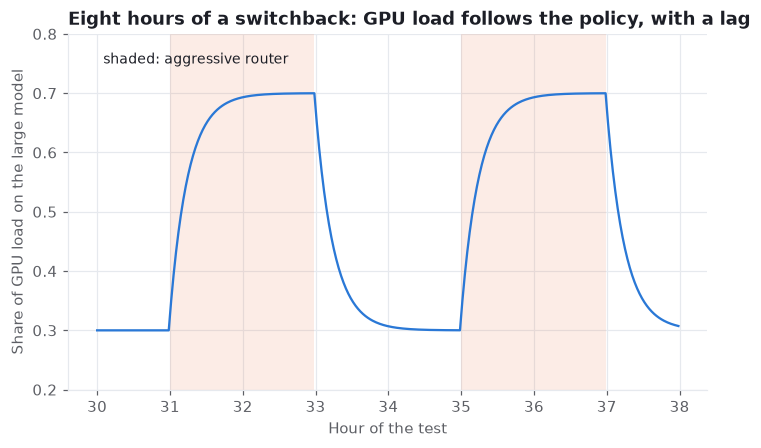

In [9]:
S = I.switchback()
window = S[(S.minute >= 60 * 30) & (S.minute < 60 * 38)]
fig, ax = plt.subplots()
hours = window.minute / 60
ax.fill_between(hours, 0, 1, where=window.aggressive, color=style.SERIES[1], alpha=0.12,
                transform=ax.get_xaxis_transform(), linewidth=0)
ax.plot(hours, window.load, color=style.SERIES[0], linewidth=1.5)
ax.set(title="Eight hours of a switchback: GPU load follows the policy, with a lag",
       xlabel="Hour of the test", ylabel="Share of GPU load on the large model", ylim=(0.2, 0.8))
ax.annotate("shaded: aggressive router", xy=(hours.iloc[0], 0.75), xytext=(4, 0),
            textcoords="offset points", fontsize=9, color=style.INK)
plt.show()

The plot shows the catch. The GPU queue doesn't empty the instant the policy flips. It reacts with a time constant of about 15 minutes: most of the way there after 20 minutes, fully settled only after most of an hour. So the first minutes of each hour still carry the *previous* hour's congestion. That **carryover** drags the two policies' measurements toward each other. The fix is a **burn-in**: ignore the first part of every block.

In [10]:
rows = {}
for burn in [0, 10, 20, 30]:
    d, se = I.switchback_estimate(S, burn_in=burn)
    rows[f"drop first {burn} min"] = {"estimate (points)": 100 * d, "std error": 100 * se}
rows["truth: launch to everyone"] = {"estimate (points)": 100 * I.global_effect(), "std error": np.nan}
rows["learner-level A/B test"] = {"estimate (points)": 100 * I.ab_effect(), "std error": np.nan}
sb = pd.DataFrame(rows).T
sb.style.format({"estimate (points)": "{:+.1f}", "std error": "{:.2f}"}, na_rep="")

,estimate (points),std error
drop first 0 min,-1.6,0.27
drop first 10 min,-2.1,0.27
drop first 20 min,-2.3,0.28
drop first 30 min,-2.5,0.29
truth: launch to everyone,-2.4,
learner-level A/B test,+1.6,


In [11]:
glue_num("sb_raw", 100 * I.switchback_estimate(S, 0)[0])
glue_num("sb_20", 100 * I.switchback_estimate(S, 20)[0])
glue_num("n_blocks", S.block.nunique())

Without a burn-in, the switchback says -1.6 points: the right sign, but too small. Dropping the first 20 minutes of each hour gives -2.3, close to the true launch effect. The learner-level A/B test pointed the wrong way entirely.

The unit of analysis is the **block**, not the lesson: 336 hourly blocks over two weeks, each one an independent coin flip. Three design rules:

- **Blocks long enough to settle**, short enough to get many of them. Measure how long carryover lasts, then make blocks several times longer. Hour-long blocks are on the short side here: the estimate keeps creeping as the burn-in grows, a sign that two-hour blocks would be better.
- **Balance time of day.** Learners behave differently at different times of day; random assignment handles it on average, and stratifying blocks by hour handles it better.
- **Use switchbacks for shared-resource changes only.** They answer "what happens to the system?", not "what happens to this learner over a month?". Learner-level effects like retention still need learner-level tests.

Agent platforms are full of shared resources: GPU pools, rate limits, caches (Chapter 3), vector indexes, a single human escalation team. Any change that shifts load on one of them is a candidate for a switchback.

## Part III, in one page

| Situation | Method | What it rests on |
|---|---|---|
| Choice depends only on logged inputs | IPW, doubly robust, double ML (Ch. 11) | No hidden reason for the choice |
| A launch at a date, with untreated comparisons | Difference-in-differences, synthetic control (Ch. 12) | Parallel trends, or a twin that fits |
| A threshold decides | Regression discontinuity (Ch. 12) | Nothing else changes at the threshold |
| You can nudge but not force | Instrumental variables (Ch. 13) | The nudge works only through the choice |
| Units affect each other | Cluster randomisation (Ch. 13) | Clusters contain the interaction |
| Treatments share a resource | Switchbacks (Ch. 13) | Blocks outlast the carryover |

> **In the wild**
>
> Encouragement designs come from medicine. Doctors were randomly sent reminders to offer patients flu vaccines; the reminder, not the vaccine, was randomised, and Hirano, Imbens, Rubin and Zhou (Hirano et al., 2000) used it as an instrument to estimate the vaccine's effect for patients the reminder moved. Switchbacks come from marketplaces: ride-hailing and delivery companies have written publicly about using them for dispatch and pricing changes, where every order competes for the same drivers.

## Pitfalls

- **Reading the intention-to-treat effect as the treatment effect.** The card's effect on retention is diluted by everyone it didn't move. Divide by the first stage (the nudge's effect on use).
- **A motivating nudge.** If the encouragement itself changes behaviour, the IV estimate is inflated.
- **Individual randomisation with network effects.** If treated users affect control users, the A/B difference measures a half-treated world.
- **Learner-level tests of shared-resource changes.** Load, latency and cache hit rates are shared by both arms. Use switchbacks.
- **Ignoring carryover.** Drop a burn-in at the start of each block, and check the estimate is stable as the burn-in grows.

## Exercises

1. **Weak card.** Change the card's effect on Juno use from 1.4 to 0.2 on the log-odds scale. How wide does the IV confidence interval get? Would you trust it?
2. **A motivating card.** Add a direct effect of the card on retention (+0.1 on the log-odds). What does the IV estimate become? Could you detect the problem from the data?
3. **Competitive leaderboard.** Make the spillover negative (−2% per treated friend). What does individual randomisation report now?
4. **Shorter blocks.** Run the switchback with 20-minute blocks. What burn-in do you need, and how much data is left? What block length would you choose?

## Further reading

Angrist, Imbens and Rubin (Angrist et al., 1996) set out what instrumental variables estimate when people don't comply. Bojinov, Simchi-Levi and Zhao (Bojinov et al., 2023) design and analyse switchback experiments with carryover. Wager (Wager, 2026) covers instrumental variables and interference with the potential outcomes notation of Chapter 1.